punto 2 taller

--- RESULTADOS DE EXACTITUD (ACCURACY) ---
k =  1 | Exactitud Entrenamiento: 1.0000 (100.00%) | Exactitud Prueba: 0.9333 (93.33%)
k =  5 | Exactitud Entrenamiento: 0.9571 (95.71%) | Exactitud Prueba: 0.9556 (95.56%)
k = 15 | Exactitud Entrenamiento: 0.9571 (95.71%) | Exactitud Prueba: 0.9333 (93.33%)


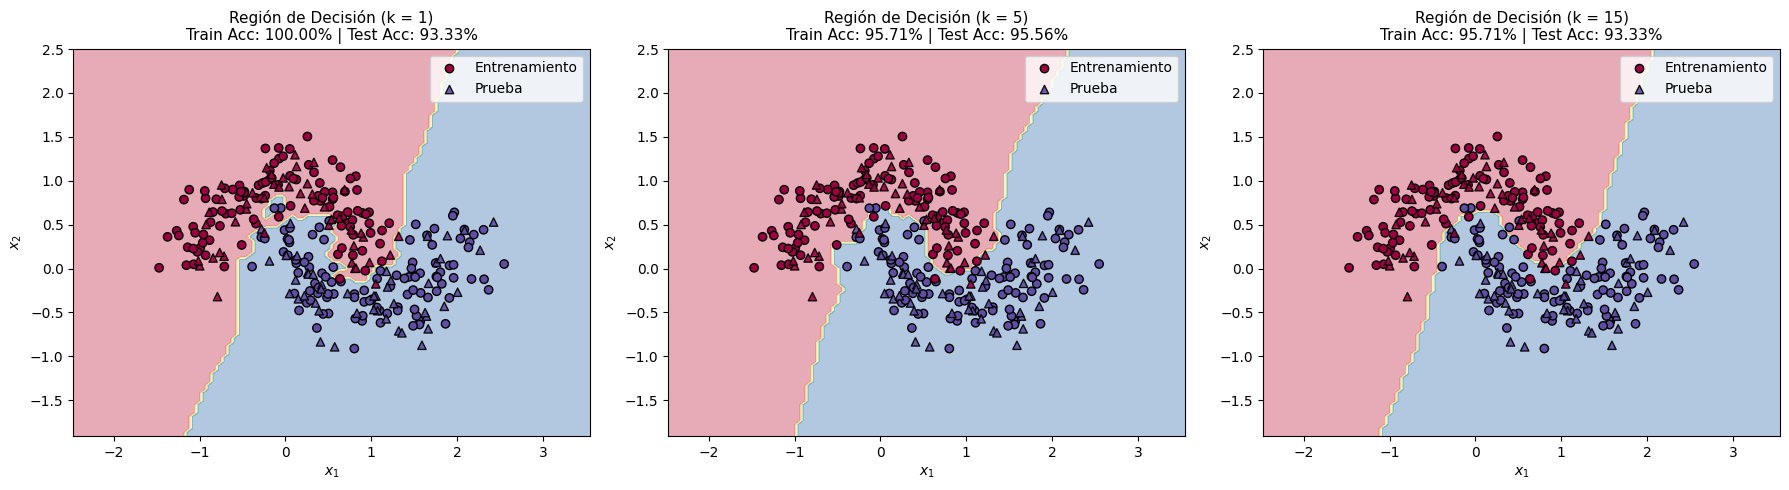

In [1]:
# ==============================================================================
# IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

# ==============================================================================
# PASO 1: GENERACIÓN DEL CONJUNTO DE DATOS (make_moons)
# ==============================================================================
# Se generan N = 300 observaciones bidimensionales con ruido = 0.20
# Semilla random_state = 42 para garantizabilidad y reproducibilidad de los resultados
X, y = make_moons(n_samples=300, noise=0.20, random_state=42)

# ==============================================================================
# PASO 2: DIVISIÓN ENTRENAMIENTO Y PRUEBA (70% / 30%)
# ==============================================================================
# test_size=0.30 asigna el 30% a prueba y el 70% a entrenamiento
# stratify=y mantiene la proporción de clases equilibrada en ambos subconjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# ==============================================================================
# PASO 3: ENTRENAMIENTO Y EVALUACIÓN PARA k ∈ {1, 5, 15}
# ==============================================================================
k_values = [1, 5, 15]
resultados = {}

print("--- RESULTADOS DE EXACTITUD (ACCURACY) ---")
for k in k_values:
    # Creación e instanciación del modelo k-NN
    knn = KNeighborsClassifier(n_neighbors=k)

    # Entrenamiento con el conjunto del 70%
    knn.fit(X_train, y_train)

    # Predicción en entrenamiento y prueba
    y_pred_train = knn.predict(X_train)
    y_pred_test = knn.predict(X_test)

    # Cálculo del Accuracy
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    # Almacenar resultados para visualización posterior
    resultados[k] = {'train': acc_train, 'test': acc_test, 'model': knn}

    print(f"k = {k:2d} | Exactitud Entrenamiento: {acc_train:.4f} ({acc_train*100:.2f}%) | Exactitud Prueba: {acc_test:.4f} ({acc_test*100:.2f}%)")

# ==============================================================================
# PASO 4: VISUALIZACIÓN DE LOS DATOS Y LAS REGIONES DE DECISIÓN
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, k_values):
    modelo = resultados[k]['model']

    # Dibujar las regiones/fronteras de decisión
    DecisionBoundaryDisplay.from_estimator(
        modelo,
        X,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.4,
        ax=ax
    )

    # Gráfica de los puntos de entrenamiento (círculos)
    ax.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train, cmap=plt.cm.Spectral,
        edgecolors='k', marker='o', label='Entrenamiento'
    )

    # Gráfica de los puntos de prueba (triángulos)
    ax.scatter(
        X_test[:, 0], X_test[:, 1],
        c=y_test, cmap=plt.cm.Spectral,
        edgecolors='k', marker='^', alpha=0.9, label='Prueba'
    )

    # Título y configuraciones del gráfico
    ax.set_title(
        f"Región de Decisión (k = {k})\n"
        f"Train Acc: {resultados[k]['train']:.2%} | Test Acc: {resultados[k]['test']:.2%}",
        fontsize=11
    )
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

punto 3 taller

In [3]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Definición de los vectores de etiquetas reales (y) y predicciones (y_hat)
y_real = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# 2. Matriz de confusión
cm = confusion_matrix(y_real, y_pred)
tn, fp, fn, tp = cm.ravel()

# 3. Cálculo de métricas requeridas
acc = accuracy_score(y_real, y_pred)
prec = precision_score(y_real, y_pred)
rec = recall_score(y_real, y_pred)
f1 = f1_score(y_real, y_pred)

# 4. Impresión y comprobación de resultados
print("=== MATRIZ DE CONFUSIÓN ===")
print(cm)
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}\n")

print("=== VERIFICACIÓN DE MÉTRICAS ===")
print(f"Accuracy (Exactitud): {acc:.4f}  -> (Manual: 7/10 = 0.7000)")
print(f"Precision (Precisión): {prec:.4f} -> (Manual: 4/5  = 0.8000)")
print(f"Recall (Sensibilidad): {rec:.4f} -> (Manual: 4/6  = 0.6667)")
print(f"F1-Score:             {f1:.4f} -> (Manual: 8/11 = 0.7273)")

=== MATRIZ DE CONFUSIÓN ===
[[3 1]
 [2 4]]
TN: 3, FP: 1, FN: 2, TP: 4

=== VERIFICACIÓN DE MÉTRICAS ===
Accuracy (Exactitud): 0.7000  -> (Manual: 7/10 = 0.7000)
Precision (Precisión): 0.8000 -> (Manual: 4/5  = 0.8000)
Recall (Sensibilidad): 0.6667 -> (Manual: 4/6  = 0.6667)
F1-Score:             0.7273 -> (Manual: 8/11 = 0.7273)
